In [1]:
import cv2
import numpy as np
from plots import plot_stenosis, plot_overlay, visualize_paths
from skeletonize import perform_skeletonization
from skeletons_postprocessing import perform_skeleton_postprocessing
from stenosis import detect_all_stenosis

In [2]:
#***************************************************************
# MAIN PIPELINE:
# 1. Skeletonization - creating skeletons of each mask
# 2. Paths - creating fragments of the vessels between bifurcations or crossings
# 3. Distances - calculating distance transform for all the pixels of the mask
# 4. Detections - final detections of stenosis ready for plotting
#***************************************************************

def find_stenosis(mask:np.ndarray, image:np.ndarray = None):
    """
    Finding and marking stenosis regions and giving some utilities helpful for debugging

    Parameters
    ----------
    mask : np.ndarray
        Vessel mask
    image : np.ndarray, optional
        Vessel image

    Returns
    -------
    stenosis_image : np.ndarray
        Stenosis visualization
    overlay : np.ndarray
        Skeleton overlayed on the provided image
    paths_img : module
        Visualization of the paths
    """
    skeleton = perform_skeletonization(mask)
    paths = perform_skeleton_postprocessing(skeleton)
    distances = cv2.distanceTransform((mask > 0).astype(np.uint8), cv2.DIST_L2, 5)
    detections = detect_all_stenosis(paths, distances, mask)

    #if user gave original image and wants additional graphs
    if image is not None:
        stenosis_image = plot_stenosis(mask, detections, image)
        overlay = plot_overlay(image, skeleton, mask)
        paths_img = visualize_paths(mask, skeleton, paths, image)
    else:
        stenosis_image = plot_stenosis(mask, detections)
        overlay = plot_overlay(mask, skeleton)
        paths_img = visualize_paths(mask, skeleton, paths)
    
    # make it return all the plots also so its convinient for the user
    return stenosis_image, overlay, paths_img

/var/folders/m3/nkgz27lx18xfj312ch2sfdzc0000gn/T/ipykernel_37100/1863815634.py:22: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  stenosis.show()
/var/folders/m3/nkgz27lx18xfj312ch2sfdzc0000gn/T/ipykernel_37100/1863815634.py:23: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  overlay.show()


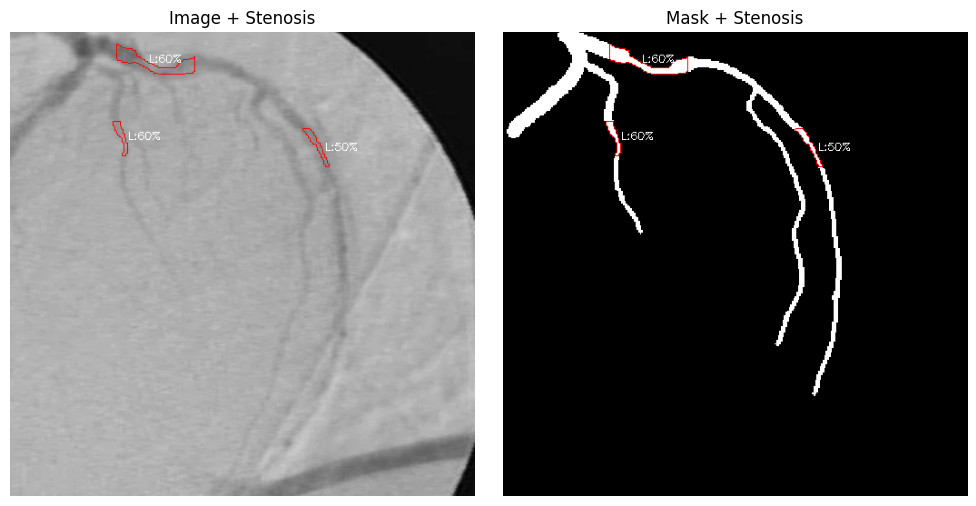

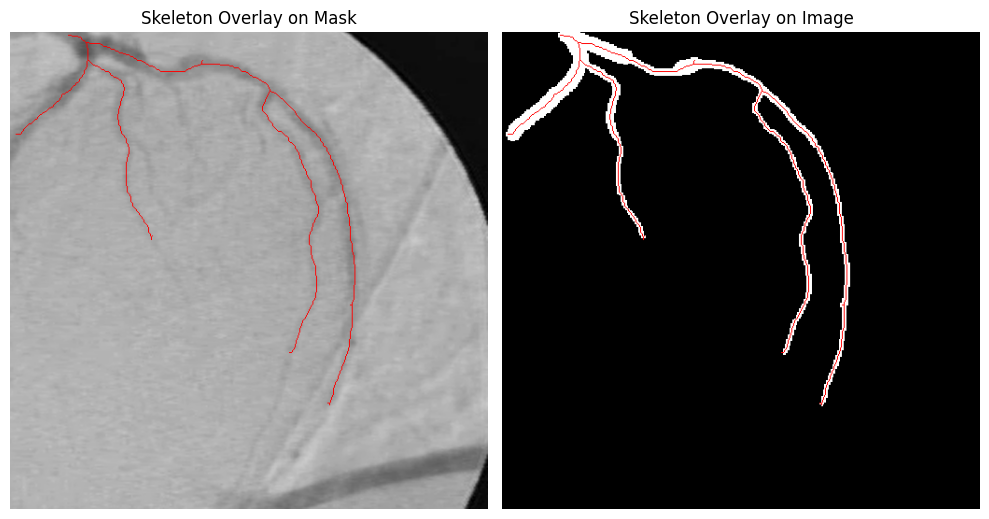

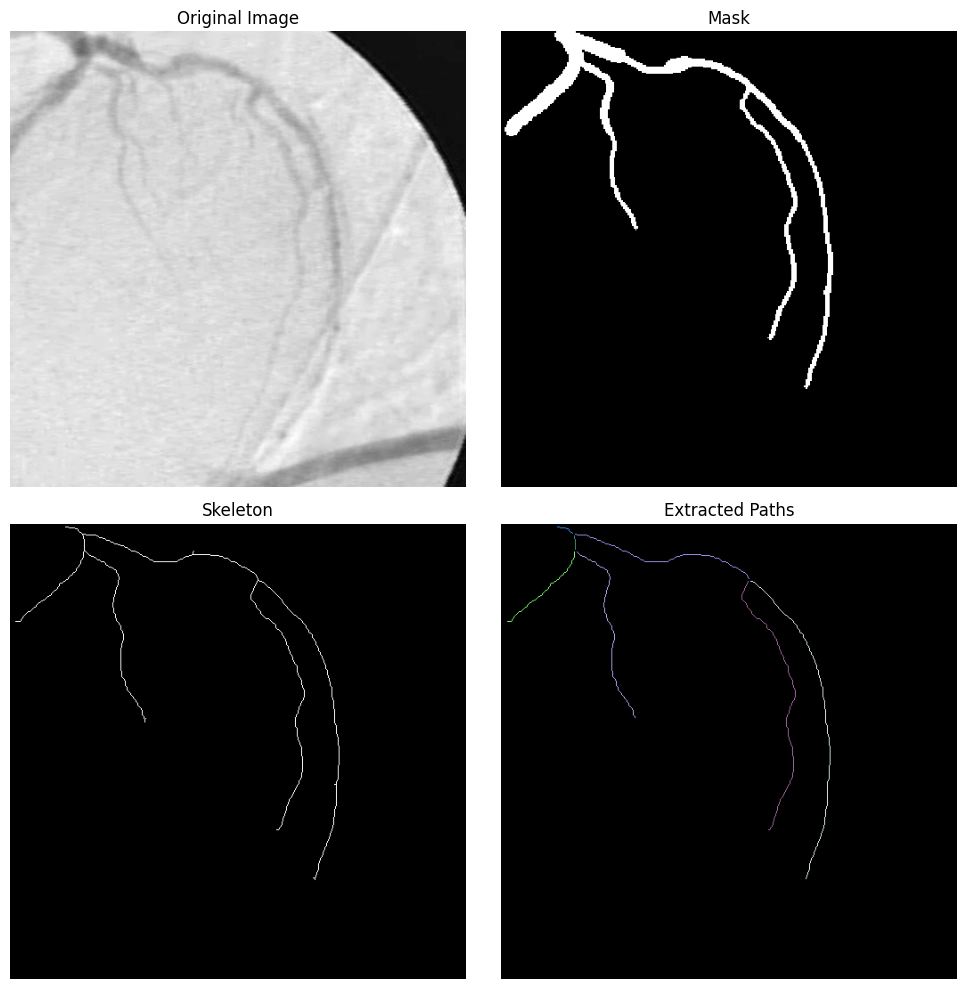

In [4]:
#***************************************************************
# Main entry of the program

# The function accepts following arguments:
# 1. mask - mask of the given vessel
# 2. image (optional) - original image for better visualization

# The function returns things You can use for visualization:
# 1. Image with stenosis
# 2. Detections - places where stenosis was detected
# 3. Paths - fragments of the vessels between the bifurcations

#***************************************************************

number = 1
mask_path = f"../data/masks/{number}.png"
image_path = f"../data/images/{number}.png"
mask = cv2.imread(mask_path, cv2.IMREAD_GRAYSCALE)
image = cv2.imread(image_path, cv2.IMREAD_GRAYSCALE)

stenosis, overlay, paths = find_stenosis(mask, image)
stenosis.show()
overlay.show()
paths.show()